# Giai đoạn 3: Mô hình mốc và kiểm tra rò rỉ cổng
Chỉ dùng tập TRAIN và Stratified 5-fold CV. Không đọc hoặc dùng test set.

In [7]:
# Nạp dữ liệu train và các hàm đánh giá
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix

sys.path.insert(0, str(Path('..').resolve()))

from src.data_prep import load_data, clean_data, get_feature_sets
from src.pipeline import make_pipeline
from src.evaluate import evaluate_cv
from src.logger import log_run

RANDOM_STATE = 42
CV = 5

df, _ = clean_data(load_data(Path('../data/RT_IOT2022')))
sets = get_feature_sets(df)
y = df['Attack_type']
X = df.drop(columns=['Attack_type'])

split = np.load('../experiments/split_indices.npz')
train_idx = np.sort(split['train_idx'])

X_train = X.iloc[train_idx]
y_train = y.iloc[train_idx]

print(f'Chỉ dùng train: {len(X_train)} dòng; CV={CV}; test không được sử dụng.')

Chỉ dùng train: 94337 dòng; CV=5; test không được sử dụng.


Notebook được dùng các chỉ số train đã lưu từ Giai đoạn 2.
Mỗi bước encoder và scaler nằm trong pipeline,
nên mỗi fold chỉ học từ phần train của fold đó.

In [8]:
# Chạy các baseline bằng CV và ghi log
runs = []
recalls = {}

def run_model(name, model, feature_set, scale=False):
    start = time.perf_counter()

    pipe = make_pipeline(
        model,
        sets[feature_set],
        scale=scale,
        sampler=None,
        random_state=RANDOM_STATE
    )

    result = evaluate_cv(
        pipe,
        X_train[sets[feature_set]],
        y_train,
        random_state=RANDOM_STATE,
        n_splits=CV
    )

    elapsed = time.perf_counter() - start

    result.update({
        'model': name,
        'feature_set': feature_set,
        'seconds': elapsed
    })

    recalls[(name, feature_set)] = result['recall_by_class']

    log_run(
        name,
        feature_set,
        CV,
        result,
        params=str(model.get_params()),
        notes=f'thời gian chạy={elapsed:.2f} giây; chỉ CV trên train'
    )

    runs.append(result)
    return result


run_model(
    'Dummy_most_frequent',
    DummyClassifier(strategy='most_frequent'),
    'NO_SRC_PORT'
)

run_model(
    'Dummy_stratified',
    DummyClassifier(strategy='stratified', random_state=RANDOM_STATE),
    'NO_SRC_PORT'
)

run_model(
    'LogisticRegression',
    LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    'NO_SRC_PORT',
    scale=True
)

for fs in sets:
    run_model(
        'DecisionTree',
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        fs
    )

Các mô hình được đánh giá bằng cùng 5 fold.
Logistic Regression được chuẩn hóa trong pipeline.
Giai đoạn 3 chưa dùng SMOTE và chưa dùng test.

,model,feature_set,macro_f1_mean,macro_f1_std,balanced_acc_mean,balanced_acc_std,mcc_mean,mcc_std,accuracy_mean,accuracy_std,train_macro_f1_mean,train_vs_cv_gap,seconds
0,Dummy_most_frequent,NO_SRC_PORT,0.072183,0.000002,0.083333,0.000000,0.000000,0.000000,0.763974,0.000034,0.072183,-3.377576e-12,25.901002
1,Dummy_stratified,NO_SRC_PORT,0.080293,0.000035,0.080344,0.000033,-0.009814,0.000052,0.591783,0.000038,0.082518,2.224948e-03,7.218530
2,LogisticRegression,NO_SRC_PORT,0.920848,0.020830,0.899844,0.025940,0.977316,0.002222,0.990799,0.000901,0.941982,2.113449e-02,102.997393
3,DecisionTree,FULL,0.944707,0.010012,0.954282,0.022676,0.993492,0.000848,0.997361,0.000344,0.998847,5.413984e-02,14.252496
4,DecisionTree,NO_SRC_PORT,0.942176,0.018151,0.946530,0.024664,0.991741,0.001155,0.996650,0.000469,0.998767,5.659065e-02,13.048489
5,DecisionTree,NO_PORTS,0.935326,0.015041,0.942604,0.022772,0.991088,0.000684,0.996385,0.000277,0.998726,6.339920e-02,12.449560


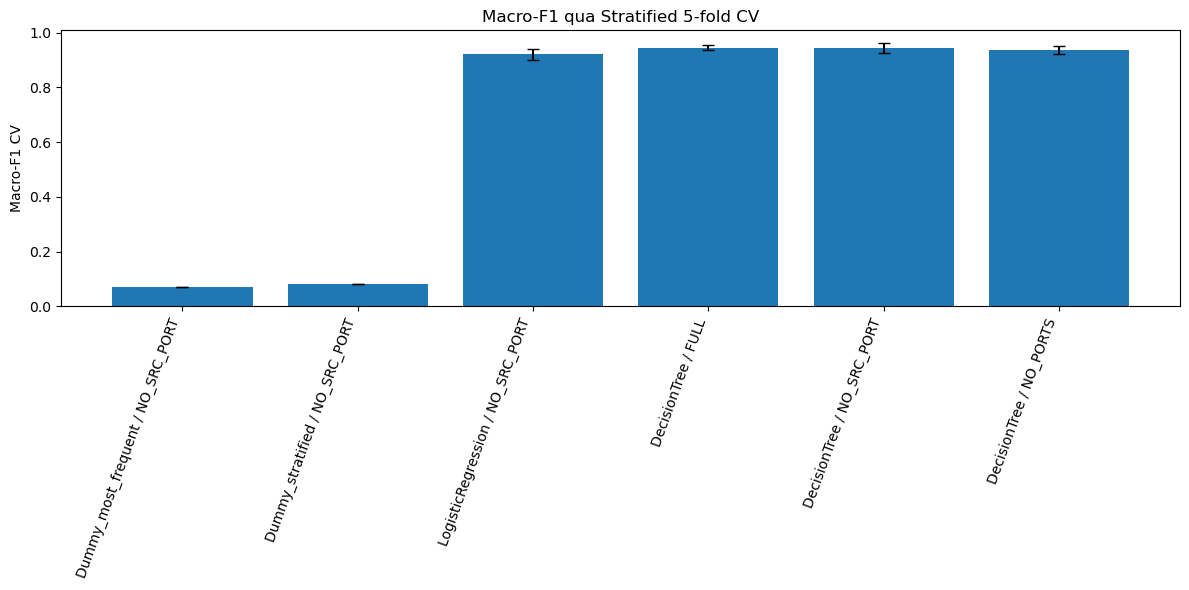

In [9]:
# Tạo bảng so sánh và biểu đồ Macro-F1
summary = pd.DataFrame([
    {k: v for k, v in r.items() if k not in {'recall_by_class', 'predictions'}}
    for r in runs
])

display(summary[[
    'model', 'feature_set',
    'macro_f1_mean', 'macro_f1_std',
    'balanced_acc_mean', 'balanced_acc_std',
    'mcc_mean', 'mcc_std',
    'accuracy_mean', 'accuracy_std',
    'train_macro_f1_mean', 'train_vs_cv_gap', 'seconds'
]])

plt.figure(figsize=(12, 6))

labels = summary['model'] + ' / ' + summary['feature_set']

plt.bar(
    labels,
    summary['macro_f1_mean'],
    yerr=summary['macro_f1_std'],
    capsize=4
)

plt.xticks(rotation=70, ha='right')
plt.ylabel('Macro-F1 CV')
plt.title('Macro-F1 qua Stratified 5-fold CV')
plt.tight_layout()
plt.savefig('../figures/04_baseline_macro_f1.png', dpi=150)
plt.show()

Bảng chứa trung bình và độ lệch chuẩn qua các fold.
Khoảng cách train-CV được dùng để nhận diện dấu hiệu overfitting,
không phải điểm test.

In [10]:
# Bảng recall Logistic Regression và Decision Tree NO_SRC_PORT
recall_table = pd.DataFrame({
    'LogisticRegression': recalls[('LogisticRegression', 'NO_SRC_PORT')],
    'DecisionTree': recalls[('DecisionTree', 'NO_SRC_PORT')]
})

class_counts = y_train.value_counts()

recall_table['so_mau_train'] = class_counts
recall_table['lop_hiem'] = recall_table['so_mau_train'] < 50

display(recall_table.sort_values('so_mau_train'))

,LogisticRegression,DecisionTree,so_mau_train,lop_hiem
NMAP_FIN_SCAN,0.818182,0.818182,22,True
Metasploit_Brute_Force_SSH,0.689655,0.793103,29,True
Wipro_bulb,0.628571,0.902857,175,False
DDOS_Slowloris,0.793427,0.913146,426,False
NMAP_TCP_scan,0.998753,0.997506,802,False
NMAP_OS_DETECTION,1.000000,1.000000,1600,False
NMAP_XMAS_TREE_SCAN,0.998134,0.998134,1608,False
NMAP_UDP_SCAN,0.982100,0.971940,2067,False
MQTT_Publish,0.997586,0.998189,3314,False
ARP_poisioning,0.938689,0.984918,6100,False


Lớp được đánh dấu hiếm khi có dưới 50 mẫu trong train.
Recall bằng 0 nghĩa là mô hình không nhận diện đúng mẫu nào
của lớp đó trong dự đoán out-of-fold.

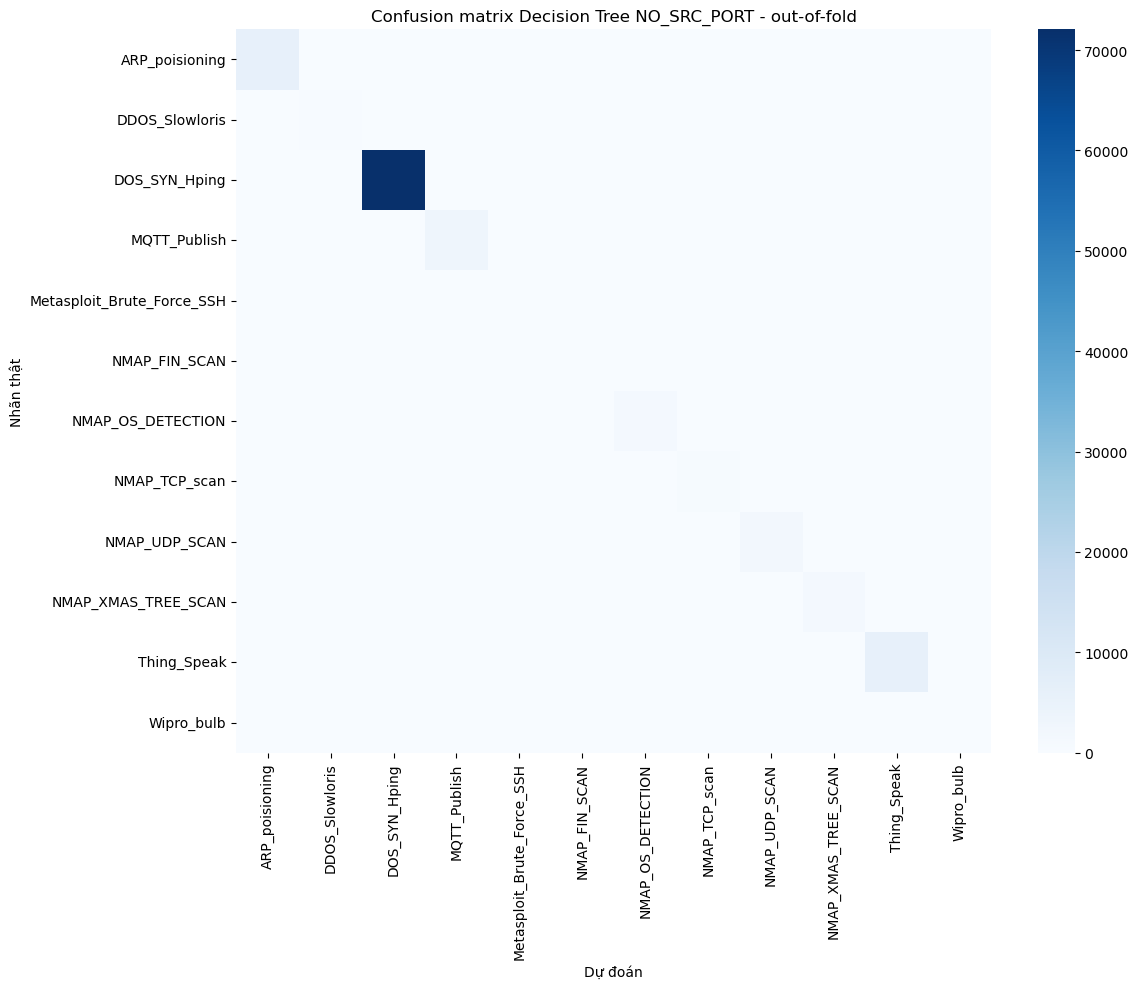

In [11]:
# Vẽ ma trận nhầm lẫn out-of-fold cho Decision Tree NO_SRC_PORT
tree_result = next(
    r for r in runs
    if r['model'] == 'DecisionTree' and r['feature_set'] == 'NO_SRC_PORT'
)

cm = confusion_matrix(
    y_train,
    tree_result['predictions'],
    labels=sorted(y_train.unique())
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    cm,
    annot=False,
    cmap='Blues',
    xticklabels=sorted(y_train.unique()),
    yticklabels=sorted(y_train.unique())
)

plt.xlabel('Dự đoán')
plt.ylabel('Nhãn thật')
plt.title('Confusion matrix Decision Tree NO_SRC_PORT - out-of-fold')

plt.tight_layout()
plt.savefig('../figures/05_confusion_matrix_tree_no_src_port.png', dpi=150)
plt.show()

Ma trận này được tạo từ dự đoán out-of-fold trên train.
Không có hàng nào lấy từ tập test.

In [12]:
# In tổng kết bằng số liệu CV thực tế
best = max(runs, key=lambda r: r['macro_f1_mean'])
dummy = max(
    (r for r in runs if r['model'].startswith('Dummy')),
    key=lambda r: r['macro_f1_mean']
)

tree_full = next(r for r in runs if r['model'] == 'DecisionTree' and r['feature_set'] == 'FULL')
tree_no_src = next(r for r in runs if r['model'] == 'DecisionTree' and r['feature_set'] == 'NO_SRC_PORT')
tree_no_ports = next(r for r in runs if r['model'] == 'DecisionTree' and r['feature_set'] == 'NO_PORTS')

worst_class = recall_table['LogisticRegression'].idxmin()
worst_recall = recall_table.loc[worst_class, 'LogisticRegression']

print('=== TỔNG KẾT GIAI ĐOẠN 3 ===')

print(f'Mô hình tốt nhất theo Macro-F1 CV: {best["model"]} / {best["feature_set"]}, Macro-F1={best["macro_f1_mean"]:.4f} ± {best["macro_f1_std"]:.4f}.')

print(f'Khoảng cách so với Dummy tốt nhất: {best["macro_f1_mean"]-dummy["macro_f1_mean"]:.4f}.')

print(f'Decision Tree bỏ id.orig_p thay đổi Macro-F1: {tree_no_src["macro_f1_mean"]-tree_full["macro_f1_mean"]:.4f}; bỏ cả hai cổng cùng thay đổi {tree_no_ports["macro_f1_mean"]-tree_full["macro_f1_mean"]:.4f}.')

print('Kết luận rò rỉ cổng: dựa trên chênh lệch Macro-F1 của ba bộ đặc trưng ở trên, cần giữ NO_SRC_PORT làm bộ chính và dùng FULL/NO_PORTS làm đối chứng.')

print(f'Lớp có recall Logistic Regression thấp nhất: {worst_class}, recall={worst_recall:.4f}; số mẫu train={int(recall_table.loc[worst_class,"so_mau_train"])}.')

print(f'Dấu hiệu overfitting của mô hình tốt nhất: train Macro-F1={best["train_macro_f1_mean"]:.4f}, CV Macro-F1={best["macro_f1_mean"]:.4f}, chênh lệch={best["train_vs_cv_gap"]:.4f}.')

=== TỔNG KẾT GIAI ĐOẠN 3 ===
Mô hình tốt nhất theo Macro-F1 CV: DecisionTree / FULL, Macro-F1=0.9447 ± 0.0100.
Khoảng cách so với Dummy tốt nhất: 0.8644.
Decision Tree bỏ id.orig_p thay đổi Macro-F1: -0.0025; bỏ cả hai cổng cùng thay đổi -0.0094.
Kết luận rò rỉ cổng: dựa trên chênh lệch Macro-F1 của ba bộ đặc trưng ở trên, cần giữ NO_SRC_PORT làm bộ chính và dùng FULL/NO_PORTS làm đối chứng.
Lớp có recall Logistic Regression thấp nhất: Wipro_bulb, recall=0.6286; số mẫu train=175.
Dấu hiệu overfitting của mô hình tốt nhất: train Macro-F1=0.9988, CV Macro-F1=0.9447, chênh lệch=0.0541.
